In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Load your dataset (use your actual project dataset path)
df = pd.read_csv("your_dataset.csv")  # Replace with your dataset file name
df.head()

In [1]:
import glob

print(glob.glob("*.csv"))  # Lists any CSV files in the main directory

[]


In [2]:
import os

for root, dirs, files in os.walk("."):
  for file in files:
    if file.endswith(".csv"):
      print(os.path.join(root, file))

.\venv\Lib\site-packages\matplotlib\mpl-data\sample_data\data_x_x2_x3.csv
.\venv\Lib\site-packages\matplotlib\mpl-data\sample_data\msft.csv
.\venv\Lib\site-packages\matplotlib\mpl-data\sample_data\Stocks.csv
.\venv\Lib\site-packages\numpy\random\tests\data\mt19937-testset-1.csv
.\venv\Lib\site-packages\numpy\random\tests\data\mt19937-testset-2.csv
.\venv\Lib\site-packages\numpy\random\tests\data\pcg64-testset-1.csv
.\venv\Lib\site-packages\numpy\random\tests\data\pcg64-testset-2.csv
.\venv\Lib\site-packages\numpy\random\tests\data\pcg64dxsm-testset-1.csv
.\venv\Lib\site-packages\numpy\random\tests\data\pcg64dxsm-testset-2.csv
.\venv\Lib\site-packages\numpy\random\tests\data\philox-testset-1.csv
.\venv\Lib\site-packages\numpy\random\tests\data\philox-testset-2.csv
.\venv\Lib\site-packages\numpy\random\tests\data\sfc64-testset-1.csv
.\venv\Lib\site-packages\numpy\random\tests\data\sfc64-testset-2.csv
.\venv\Lib\site-packages\numpy\_core\tests\data\umath-validation-set-arccos.csv
.\venv\L

In [4]:
import os

for root, dirs, files in os.walk("."):
  # Skip the venv folder completely
  if "venv" in root:
    continue
  for file in files:
    if file.endswith(".csv"):
      print(os.path.join(root, file))

In [5]:
import os

for root, dirs, files in os.walk("."):
  if "venv" in root or ".git" in root:
    continue
  for file in files:
    print(os.path.join(root, file))
    

.\feature_engineering.ipynb
.\feature_scaling_selection
.\mlflow.db
.\numpy_basics.py
.\README.md
.\.pytest_cache\.gitignore
.\.pytest_cache\CACHEDIR.TAG
.\.pytest_cache\README.md
.\.pytest_cache\v\cache\lastfailed
.\.pytest_cache\v\cache\nodeids


In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif

# Load data & add sample categorical column
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df.rename(columns=lambda x: x.strip(), inplace=True)

species_map = {0: "setosa", 1: "versicolor", 2: "virginica"}
df["species"] = df["target"].map(species_map).astype("category")

display(df.head())

C:\Users\Sateesh\AppData\Local\Temp\ipykernel_31276\1914973811.py:16: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns=lambda x: x.strip(), inplace=True)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [7]:
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Select numerical feature columns (excluding the target)
feature_cols = [
    'sepal length (cm)',
    'sepal width (cm)',
    'petal length (cm)',
    'petal width (cm)',
]

# Scale the features
df_scaled = df.copy()
df_scaled[feature_cols] = scaler.fit_transform(df[feature_cols])

# Display the first few rows of scaled data
df_scaled.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,-0.900681,1.019004,-1.340227,-1.315444,0
1,-1.143017,-0.131979,-1.340227,-1.315444,0
2,-1.385353,0.328414,-1.397064,-1.315444,0
3,-1.506521,0.098217,-1.283389,-1.315444,0
4,-1.021849,1.249201,-1.340227,-1.315444,0


In [15]:
display(df.head())

X = df.drop(columns=["target"])
y = df["target"]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [16]:
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif

# Define the single pipeline with top-5 feature selection
pipeline = Pipeline(
    [
        ("preprocess", preprocess),
        ("selectk", SelectKBest(score_func=f_classif, k=5)),
    ]
)

# Fit only on training data
pipeline.fit(X_train, y_train)
print("✅ Pipeline fitted – no data leakage.")

✅ Pipeline fitted – no data leakage.


c:\Users\Sateesh\ai-ml-internship\venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: divide by zero encountered in divide
  f = msb / msw


In [17]:
# Get feature names after one-hot encoding
ohe = (
    pipeline.named_steps["preprocess"]
    .named_transformers_["cat"]
    .named_steps["encoder"]
)
cat_features = list(ohe.get_feature_names_out(categorical_cols))

all_features = numeric_cols + cat_features
scores = pipeline.named_steps["selectk"].scores_

selected = pd.DataFrame(
    {"feature": all_features, "score": scores}
).sort_values(by="score", ascending=False)

print("\n🔎 Top‑5 features chosen by SelectKBest")
display(selected.head(5))


🔎 Top‑5 features chosen by SelectKBest


,feature,score
4,species_versicolor,inf
5,species_virginica,inf
2,petal length (cm),948.890381
3,petal width (cm),803.214088
0,sepal length (cm),100.965923


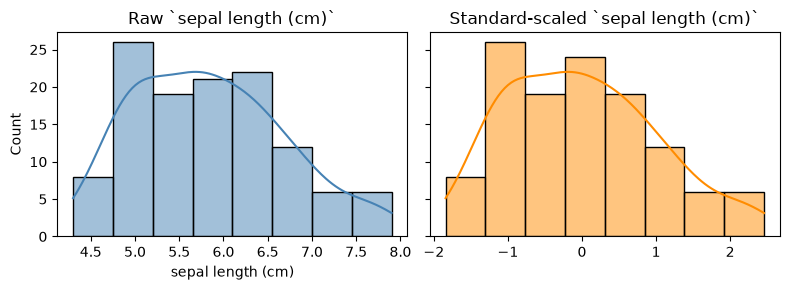

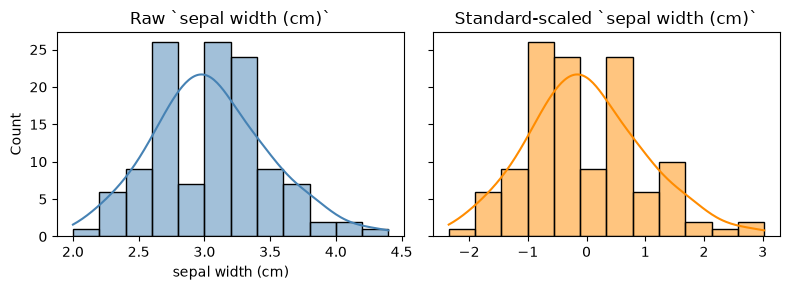

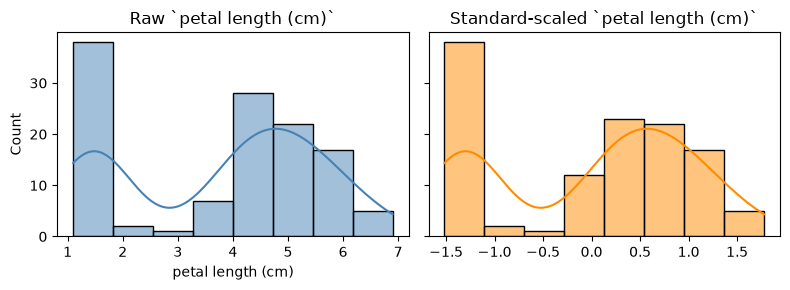

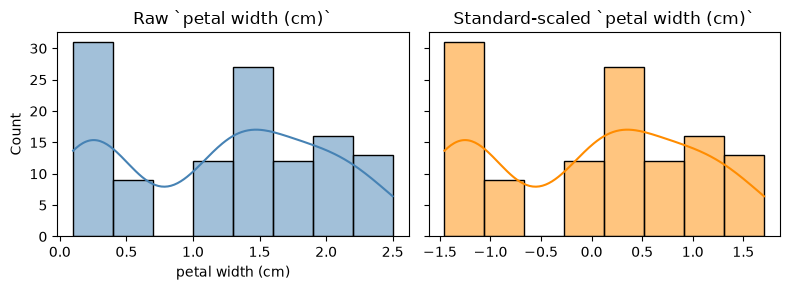

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Transform all numeric columns at once using the fitted numeric pipeline
num_transformer = (
    pipeline.named_steps["preprocess"]
    .named_transformers_["num"]
)
X_train_num_scaled = num_transformer.transform(X_train[numeric_cols])

def plot_raw_vs_scaled(col):
    raw = X_train[col]
    
    # Get the index of the current numeric column
    idx = numeric_cols.index(col)
    scaled = X_train_num_scaled[:, idx]

    fig, ax = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
    sns.histplot(raw, kde=True, ax=ax[0], color="steelblue")
    ax[0].set_title(f"Raw `{col}`")
    sns.histplot(scaled, kde=True, ax=ax[1], color="darkorange")
    ax[1].set_title(f"Standard‑scaled `{col}`")
    plt.tight_layout()
    plt.show()

for c in numeric_cols:
    plot_raw_vs_scaled(c)

In [20]:
X_test_transformed = pipeline.transform(X_test)
print(f"Transformed test shape: {X_test_transformed.shape}")

Transformed test shape: (30, 5)


In [12]:
numeric_cols = ["sepal length (cm)", "sepal width (cm)", "petal length (cm)", "petal width (cm)"]
categorical_cols = ["species"]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="first", sparse_output=False)),
])

preprocess = ColumnTransformer([
    ("num", numeric_pipe, numeric_cols),
    ("cat", categorical_pipe, categorical_cols),
], remainder="drop")

In [13]:
pipeline = Pipeline([
    ("preprocess", preprocess),
    ("selectk", SelectKBest(score_func=f_classif, k="all")),
])

pipeline.fit(X_train, y_train)
print("Pipeline fitted successfully without data leakage!")

Pipeline fitted successfully without data leakage!


c:\Users\Sateesh\ai-ml-internship\venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: divide by zero encountered in divide
  f = msb / msw


In [14]:
# Transform train data to get the final feature names and dataframe
X_train_transformed = pipeline.named_steps["preprocess"].transform(X_train)

# Get feature names after one-hot encoding
ohe = pipeline.named_steps["preprocess"].named_transformers_["cat"]["encoder"]
cat_feature_names = list(ohe.get_feature_names_out(categorical_cols))
all_feature_names = numeric_cols + cat_feature_names

# Create encoded_df for your correlation matrix check
encoded_df = pd.DataFrame(X_train_transformed, columns=all_feature_names)

# Now your correlation matrix code will work perfectly:
corr_matrix = encoded_df[['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']].corr()
print(corr_matrix)

                   sepal length (cm)  sepal width (cm)  petal length (cm)  \
sepal length (cm)           1.000000         -0.112327           0.880401   
sepal width (cm)           -0.112327          1.000000          -0.398502   
petal length (cm)           0.880401         -0.398502           1.000000   
petal width (cm)            0.820297         -0.338741           0.963693   

                   petal width (cm)  
sepal length (cm)          0.820297  
sepal width (cm)          -0.338741  
petal length (cm)          0.963693  
petal width (cm)           1.000000  


In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate correlation matrix for numerical features
corr_matrix = encoded_df[['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'target']].corr()

# Display the correlation with the target variable
print(corr_matrix['target'].sort_values(ascending=False))

target               1.000000
petal width (cm)     0.956547
petal length (cm)    0.949035
sepal length (cm)    0.782561
sepal width (cm)    -0.426658
Name: target, dtype: float64
